# Task 2: Exploratory Data Analysis (EDA)

## Project Overview

Exploratory Data Analysis (EDA) is the process of examining data to understand its structure, identify patterns, detect unusual values, and discover useful insights.

In this project, I analyzed a cleaned Online Retail dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn. The analysis focuses on transaction sales, country performance, monthly trends, product performance, and negative-quantity records.

### Dataset Information

- **Rows:** 536,641
- **Columns:** 8
- **Main columns:** InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, and Country
- **Additional column:** Sales, calculated as Quantity × UnitPrice

The dataset contains missing product descriptions and customer IDs, as well as negative quantities and unusual transaction values. These were considered during the analysis rather than automatically removed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import zipfile
import os

In [3]:
with zipfile.ZipFile("cleaned_online_retail.zip", "r") as zip_ref:
    print(zip_ref.namelist())

['cleaned_online_retail.csv']


In [4]:
with zipfile.ZipFile("cleaned_online_retail.zip", "r") as zip_ref:
    csv_file = zip_ref.namelist()[0]
    df = pd.read_csv(zip_ref.open(csv_file))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
print("Dataset shape:", df.shape)

df.head()

Dataset shape: (536641, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [11]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.8+ MB


In [10]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,536641.000000,536641.000000,401604.000000
mean,9.620029,4.632656,15281.160818
std,219.130156,97.233118,1714.006089
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13939.000000
50%,3.000000,2.080000,15145.000000
75%,10.000000,4.130000,16784.000000
max,80995.000000,38970.000000,18287.000000


In [12]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype("Int64")

In [13]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object

In [14]:
df["Sales"] = df["Quantity"] * df["UnitPrice"]

df[["Quantity", "UnitPrice", "Sales"]].head()

,Quantity,UnitPrice,Sales
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [15]:
df[["Quantity", "UnitPrice", "Sales"]].describe()

,Quantity,UnitPrice,Sales
count,536641.000000,536641.000000,536641.000000
mean,9.620029,4.632656,18.123861
std,219.130156,97.233118,380.656263
min,-80995.000000,-11062.060000,-168469.600000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.080000,9.870000
75%,10.000000,4.130000,17.400000
max,80995.000000,38970.000000,168469.600000


### Interpretation of Descriptive Statistics

The average quantity per record is approximately 9.62 units, while the median is 3 units. This difference suggests that some records contain unusually large quantities.

The average recorded sales value is approximately 18.12, compared with a median of 9.87. The minimum and maximum values show that the dataset includes both negative transactions and unusually large positive values.

These differences indicate that the data is widely spread and that extreme values can influence the mean. Therefore, the median and distribution charts are also useful for understanding typical transaction values.

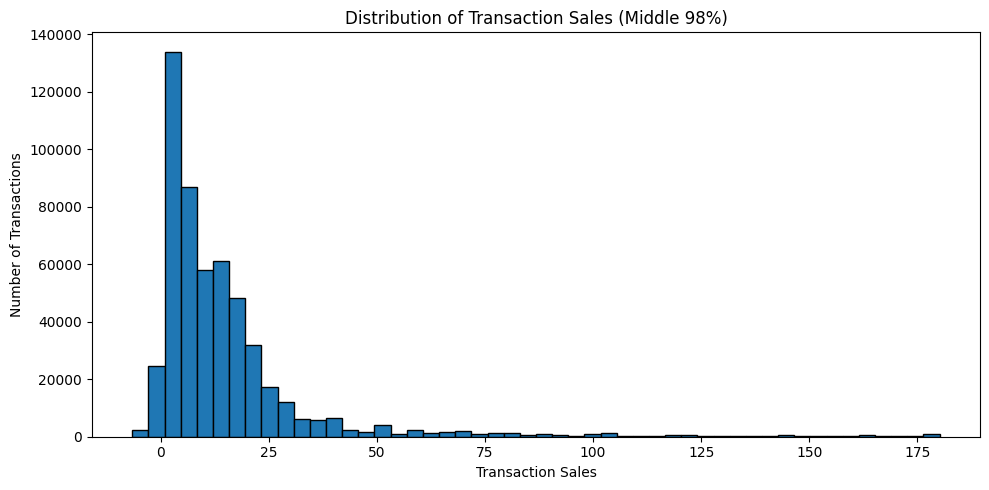

In [16]:
lower = df["Sales"].quantile(0.01)
upper = df["Sales"].quantile(0.99)

sales_filtered = df.loc[
    df["Sales"].between(lower, upper),
    "Sales"
]

plt.figure(figsize=(10, 5))
plt.hist(sales_filtered, bins=50, edgecolor="black")

plt.title("Distribution of Transaction Sales (Middle 98%)")
plt.xlabel("Transaction Sales")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Insight 1: Distribution of Transaction Sales

The transaction sales distribution is right-skewed. Most transactions have relatively low recorded sales values, while a smaller number have much higher values.

Negative transaction values are also present and may represent returns or adjustments. The chart displays the middle 98% of sales values to make the main distribution easier to examine. The excluded extreme values remain in the original dataset.

This pattern suggests that the mean alone may not represent a typical transaction accurately.

In [17]:
country_sales = (
    df.groupby("Country")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Sales, dtype: float64

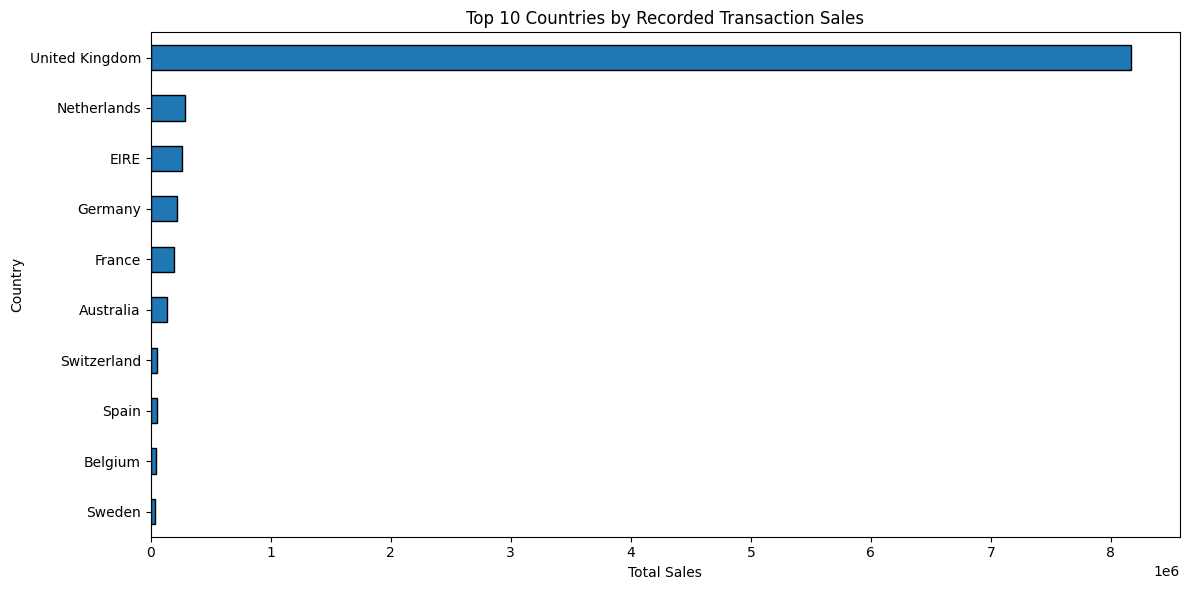

In [18]:
plt.figure(figsize=(12, 6))

country_sales.head(10).sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Countries by Recorded Transaction Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Insight 2: Sales by Country

The United Kingdom recorded the highest net transaction sales, totaling approximately 8.17 million. The Netherlands ranked second at approximately 284,662, followed by EIRE, Germany, and France.

The large difference indicates that the United Kingdom is the dominant market in this dataset. The business could investigate the factors driving UK sales and explore opportunities in other countries.

These figures represent net recorded transaction sales, including negative values, rather than profit.

In [19]:
# Extract the month from each invoice date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculate monthly recorded transaction sales
monthly_sales = (
    df.groupby("YearMonth")["Sales"]
      .sum()
      .sort_index()
)

monthly_sales

YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Sales, dtype: float64

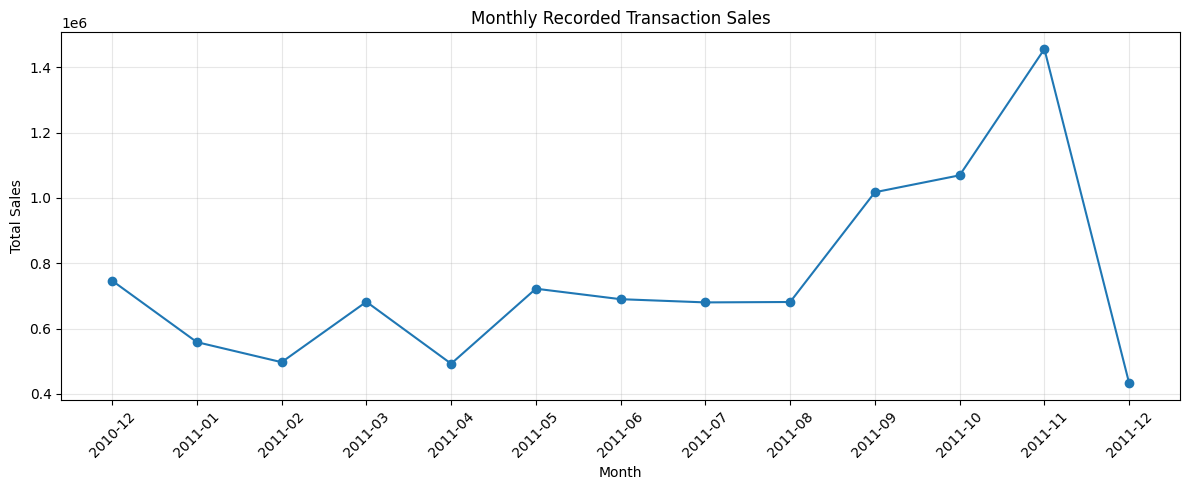

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Recorded Transaction Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Insight 3: Monthly Sales Trends

Monthly recorded sales increased substantially from August through November 2011. November recorded the highest total, at approximately 1.46 million.

Sales fluctuated during the earlier months, with lower totals in February and April. December recorded approximately 432,701, but the dataset ends on 9 December 2011, making it an incomplete month.

The November increase may reflect seasonal demand or other business factors, but additional analysis would be required to determine the cause.

In [21]:
# Calculate total quantity for each product
product_sales = (
    df.groupby("Description")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

product_sales.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64

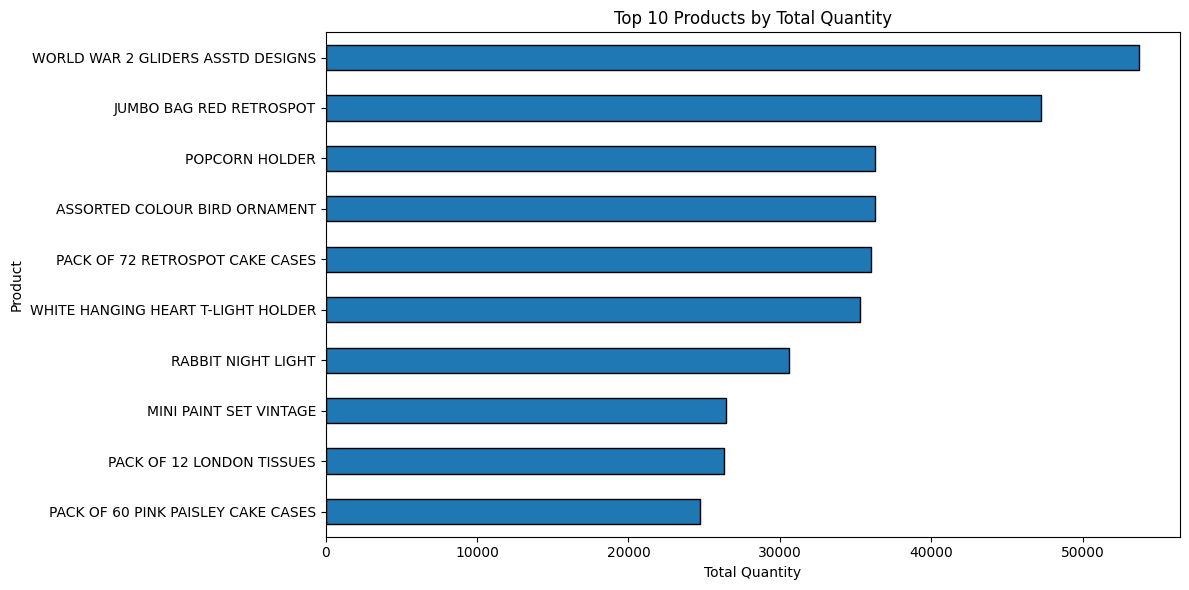

In [22]:
top_products = product_sales.head(10).sort_values()

plt.figure(figsize=(12, 6))

top_products.plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Products by Total Quantity")
plt.xlabel("Total Quantity")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

### Insight 4: Top Products by Quantity

WORLD WAR 2 GLIDERS ASSTD DESIGNS had the highest net recorded quantity, at 53,751 units, followed by JUMBO BAG RED RETROSPOT at 47,260 units.

Several other products recorded net quantities above 30,000 units. These products may warrant further investigation for inventory planning and promotions.

The figures include negative quantities, so they represent net recorded quantities rather than necessarily the number of units sold to customers.

In [23]:
# Count transactions with negative quantities
negative_quantity = (df["Quantity"] < 0).sum()

# Count invoices beginning with C
cancelled_invoices = (
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

# Count negative-quantity records with a C invoice number
negative_with_c = (
    (df["Quantity"] < 0)
    & df["InvoiceNo"].astype(str).str.startswith("C")
).sum()

print("Negative-quantity records:", negative_quantity)
print("Records with invoice numbers starting with C:", cancelled_invoices)
print("Negative-quantity records with C invoice numbers:", negative_with_c)

Negative-quantity records: 10587
Records with invoice numbers starting with C: 9251
Negative-quantity records with C invoice numbers: 9251


### Insight 5: Negative Quantities and Invoice Prefixes

The dataset contains 10,587 records with negative quantities. Of these, 9,251 have invoice numbers beginning with the letter C, while 1,336 do not.

This indicates a strong association between the C invoice prefix and negative-quantity records in this dataset. Some negative-quantity records without the prefix also have missing descriptions and zero unit prices.

These records should be investigated separately when analyzing sales, returns, and adjustments. They should not automatically be deleted because they may contain useful business information.

In [24]:
# Inspect some negative-quantity records
df.loc[
    df["Quantity"] < 0,
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Sales"]
].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,Sales
141,C536379,Discount,-1,27.50,-27.50
154,C536383,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,-4.65
235,C536391,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,-19.80
236,C536391,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,-6.96
237,C536391,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,-6.96
238,C536391,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,-6.96
239,C536391,CHICK GREY HOT WATER BOTTLE,-12,3.45,-41.40
240,C536391,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,-19.80
241,C536391,PLASTERS IN TIN SKULLS,-24,1.65,-39.60
916,C536506,JAM MAKING SET WITH JARS,-6,4.25,-25.50


In [25]:
df.loc[
    (df["Quantity"] < 0)
    & ~df["InvoiceNo"].astype(str).str.startswith("C"),
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Sales"]
].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,Sales
2362,536589,NaN,-10,0.0,-0.0
4286,536764,NaN,-38,0.0,-0.0
7086,536996,NaN,-20,0.0,-0.0
7087,536997,NaN,-20,0.0,-0.0
7088,536998,NaN,-6,0.0,-0.0
7090,537000,NaN,-22,0.0,-0.0
7091,537001,NaN,-6,0.0,-0.0
7093,537003,NaN,-2,0.0,-0.0
7094,537004,NaN,-30,0.0,-0.0
7095,537005,NaN,-70,0.0,-0.0


In [26]:
total_sales = df["Sales"].sum()

uk_sales = df.loc[
    df["Country"] == "United Kingdom", "Sales"
].sum()

uk_percentage = (uk_sales / total_sales) * 100

print(f"Total recorded sales: {total_sales:,.2f}")
print(f"UK recorded sales: {uk_sales:,.2f}")
print(f"UK contribution: {uk_percentage:.2f}%")

Total recorded sales: 9,726,006.95
UK recorded sales: 8,167,128.18
UK contribution: 83.97%


### Insight 6: Dependence on the UK Market

The United Kingdom contributed approximately 83.97% of total net recorded transaction sales. UK sales were approximately 8.17 million, compared with total recorded sales of approximately 9.73 million across all countries.

This indicates a strong concentration of recorded sales in the UK. The business could investigate opportunities to diversify sales across other markets, while considering differences in customer demand, costs, and profitability.

This percentage measures the UK's share of net recorded transaction sales, not profit.

In [27]:
top_products_by_sales = (
    df.groupby("Description")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

top_products_by_sales.head(10)

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: Sales, dtype: float64

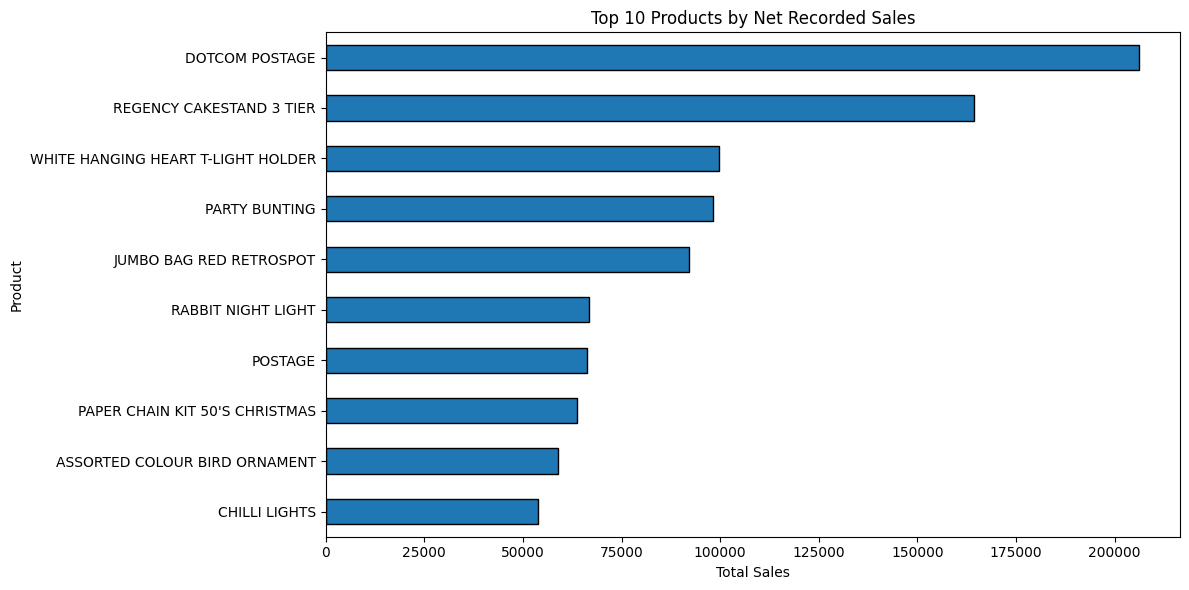

In [28]:
top_10_sales = top_products_by_sales.head(10).sort_values()

plt.figure(figsize=(12, 6))

top_10_sales.plot(kind="barh", edgecolor="black")

plt.title("Top 10 Products by Net Recorded Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

### Insight 7: Top Products by Net Recorded Sales

DOTCOM POSTAGE had the highest net recorded sales value, at approximately 206,245, followed by REGENCY CAKESTAND 3 TIER at approximately 164,459.

WHITE HANGING HEART T-LIGHT HOLDER and PARTY BUNTING also ranked highly. Postage-related entries appear among the top results, so shipping charges should be distinguished from merchandise when evaluating product performance.

These totals represent net recorded transaction values and should not be interpreted as profit.

In [31]:
# Calculate totals for every product
product_summary = (
    df.groupby("Description")
      .agg(
          Net_Quantity=("Quantity", "sum"),
          Net_Sales=("Sales", "sum")
      )
)

# Keep products appearing in either top-10 list
comparison = product_summary.loc[
    product_summary.index.isin(top_quantity.index)
    | product_summary.index.isin(top_sales.index)
].copy()

# Sort by net sales
comparison.sort_values(
    "Net_Sales", ascending=False
)

,Net_Quantity,Net_Sales
Description,,
DOTCOM POSTAGE,707,206245.48
REGENCY CAKESTAND 3 TIER,13007,164459.49
WHITE HANGING HEART T-LIGHT HOLDER,35298,99612.42
PARTY BUNTING,18010,98243.88
JUMBO BAG RED RETROSPOT,47260,92175.79
RABBIT NIGHT LIGHT,30631,66661.63
POSTAGE,3003,66230.64
PAPER CHAIN KIT 50'S CHRISTMAS,18876,63715.24
ASSORTED COLOUR BIRD ORNAMENT,36282,58792.42


### Insight 8: Product Quantity Versus Sales Value

The product with the highest net quantity was WORLD WAR 2 GLIDERS ASSTD DESIGNS, at 53,751 units. However, its net recorded sales value was approximately 13,560.

In contrast, DOTCOM POSTAGE had the highest net recorded sales value, at approximately 206,245, with a net quantity of 707. JUMBO BAG RED RETROSPOT performed strongly in both measures, with 47,260 units and approximately 92,176 in net sales.

These results demonstrate that products with the highest quantities do not necessarily generate the highest recorded sales values. Postage entries should be analyzed separately from merchandise.

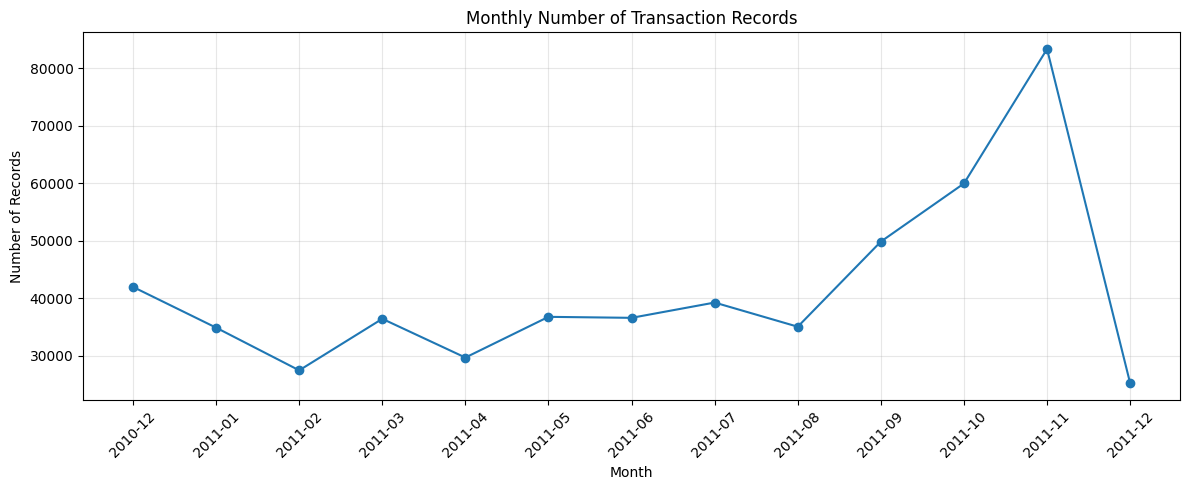

In [32]:
monthly_transactions = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))
      .size()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_transactions.index.astype(str),
    monthly_transactions.values,
    marker="o"
)

plt.title("Monthly Number of Transaction Records")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Insight 9: Monthly Transaction Activity

November 2011 had the highest number of transaction records, at approximately 83,000, and also had the highest monthly net recorded sales value.

Transaction activity increased substantially from August through November. December recorded fewer rows, but the dataset ends on 9 December, so the month is incomplete.

This pattern suggests that higher transaction activity may have contributed to November's higher sales total. Further analysis comparing unique invoices and average transaction values could help explain the relationship.

## Conclusion

The exploratory analysis revealed several useful patterns in the Online Retail dataset.

The United Kingdom dominates net recorded transaction sales, contributing approximately 83.97% of the total. November 2011 recorded the highest monthly sales value and transaction-record count. Product rankings also differed depending on whether products were compared by net quantity or net sales value.

The analysis identified a right-skewed sales distribution, negative-quantity records, and postage-related entries that require careful interpretation.

This project strengthened my understanding of data exploration, descriptive statistics, grouping and aggregation with Pandas, time-series analysis, and data visualization. The findings can support further investigation into sales performance, product demand, and market opportunities.

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.